# irAE Prediction — Feature Analysis of the Final Model

**Purpose.** Notebook 4 of 4. Notebook 3 selected the final model by nested cross-validation:
3 PLS components from the 40 baseline cytokines → L2 logistic regression. This notebook asks
**which baseline features drive that model's predictions, in which direction, and how stably.**

**Dataset.** `Khan_workable.csv` — 146 immune-checkpoint-inhibitor patients from Khan et al.,
*J Immunother Cancer* 2025 (Zenodo doi:10.5281/zenodo.17943391, CC BY 4.0). Outcome:
`iraE_occurrence` = 1 for a **grade ≥2 irAE** (n = 79), 0 for grade 0–1 (n = 67). Baseline samples only.

**Method in brief.**

1. **PLS weights + coefficients** — what each component is made of and which way it points,
   with components sign-aligned across folds.
2. **Permutation importance** — how much held-out AUC drops when one input is shuffled.
3. **Exploratory follow-ups** — univariate tests and a joint regression of cytokine groups
   (descriptive only; see the note in that section).

Analyses 1–2 are computed **inside each of 20 train/test splits** (5-fold stratified CV × 4
repeats, seed 42) and reported as mean ± SD, so a feature is only reported if it recurs across
resamples.

> n = 146. PLS weights and importances describe **associations inside a multivariate model of
> correlated predictors** — not causal effects, and not the effect of a cytokine on its own.

In [1]:
import os, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import mannwhitneyu
import statsmodels.api as sm

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

import sklearn, scipy, statsmodels
print("scikit-learn", sklearn.__version__, "| scipy", scipy.__version__,
      "| statsmodels", statsmodels.__version__, "| numpy", np.__version__)

SEED = 42
pd.set_option("display.width", 160)

scikit-learn 1.6.1 | scipy 1.16.3 | statsmodels 0.15.0 | numpy 2.4.6


## 1. Data

The CSV is read from the public GitHub repository (or from a local copy if one is present).
Cleaning is identical to notebooks 2–3: ICI regimen → mechanism class, cancer type →
Lung / Melanoma / Other.

In [2]:
RAW_URL = ("https://raw.githubusercontent.com/vishnusrikant/ImmunoTherapy/main/"
           "ActionableData/Khan_workable.csv")
df = pd.read_csv("Khan_workable.csv" if os.path.exists("Khan_workable.csv") else RAW_URL)

def ici_mechanism(drug):
    d = str(drug).lower()
    return "CTLA4_or_combo" if ("ipilimumab" in d or "+" in d) else "PD1_PDL1_mono"

def cancer_group(ct):
    ct = str(ct)
    if "Lung" in ct:
        return "Lung"
    return "Melanoma" if ct == "Melanoma" else "Other"

df["ici_mechanism"] = df["ici_drug"].map(ici_mechanism)
df["cancer_group"] = df["cancer_type"].map(cancer_group)

y = df["iraE_occurrence"].astype(int)
X = df.drop(columns=["patient_id", "iraE_occurrence", "ici_drug", "cancer_type"])

categorical_cols = ["gender", "ethnicity", "race", "cancer_group", "ici_mechanism"]
ana_cols = ["ana_titer_baseline", "ana_titer_missing"]
cytokine_cols = [c for c in X.columns if c not in categorical_cols + ana_cols]

print(f"{X.shape[0]} patients | {len(cytokine_cols)} cytokines | "
      f"grade >=2 irAE: {int(y.sum())}, grade 0-1: {int((1 - y).sum())}")

146 patients | 40 cytokines | grade >=2 irAE: 79, grade 0-1: 67


## 2. The model being interpreted

Same pipeline as notebook 3's winner, with every learned step inside the pipeline so it is
refit on each training fold:

- **Cytokines:** median impute → log(x + 1) → standardize → **PLS, 3 components**
- **ANA (value + missingness flag):** median impute → log(x + 1) → standardize
- **Categoricals:** most-frequent impute → one-hot (categories with < 5 patients pooled)
- **Classifier:** L2 logistic regression, **C fixed at 0.1**

Notebook 3 tuned C separately in every fold. For interpretation we need one consistent model
across folds, so C is fixed at 0.1 — the best fixed value in notebook 2's screen.

In [3]:
class PLSFeatures(BaseEstimator, TransformerMixin):
    # Adapter so sklearn's PLSRegression can sit inside a ColumnTransformer.
    # All of the maths is PLSRegression's; it is fit on the training fold only.
    def __init__(self, n_components=3):
        self.n_components = n_components
    def fit(self, X, y=None):
        self.pls_ = PLSRegression(n_components=self.n_components)
        self.pls_.fit(X, np.asarray(y, dtype=float))
        return self
    def transform(self, X):
        return self.pls_.transform(X)

def log1p_step():
    return FunctionTransformer(np.log1p, feature_names_out="one-to-one")

def make_model(C=0.1, n_components=3):
    prep = ColumnTransformer([
        ("cyto", Pipeline([("impute", SimpleImputer(strategy="median")),
                           ("log1p", log1p_step()),
                           ("scale", StandardScaler()),
                           ("pls", PLSFeatures(n_components))]), cytokine_cols),
        ("ana", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("log1p", log1p_step()),
                          ("scale", StandardScaler())]), ana_cols),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                   min_frequency=5, sparse_output=False))]),
         categorical_cols),
    ])
    return Pipeline([("prep", prep), ("clf", LogisticRegression(C=C, max_iter=5000))])

## 3. Fit across 20 splits: weights, coefficients, permutation importance

For every split we fit the model on the training fold and record three things.

**PLS weights** (`x_weights_`, 40 × 3). One weight per cytokine per component: how much that
cytokine contributes to the component. *(PLS "weights" and "loadings" are technically different
quantities; these are the weights.)*

**Regression coefficients.** One per component: how much the component shifts the predicted
log-odds of a grade ≥2 irAE. A cytokine's effect through a component is **weight × coefficient**,
so the *direction* of association is the sign of that product.

**Sign alignment.** The sign of a PLS component is arbitrary — a component and its negation give
identical predictions — so the same pattern can come out as (+weights, +coefficient) in one fold
and (−weights, −coefficient) in the next. Averaging those raw would cancel them to zero. So, per
component and per fold: if the reference cytokine **Eotaxin-2/CCL24** has a negative weight, the
component's **40 weights and its coefficient are each multiplied by −1**. The two sign changes
cancel, so predictions are unchanged; only the orientation becomes consistent.

**Permutation importance.** With the fitted model frozen, one input variable at a time is
shuffled among the **held-out** patients (15 shuffles each) and the drop in ROC AUC recorded.
It is measured on held-out patients so it reflects what helps on unseen patients, not what the
model memorized.

In [4]:
N_SPLITS, N_REPEATS, N_PERM = 5, 4, 15
cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
n_fits = N_SPLITS * N_REPEATS

ANCHOR = "Eotaxin-2/ CCL24"
anchor_idx = cytokine_cols.index(ANCHOR)

W      = np.zeros((n_fits, len(cytokine_cols), 3))   # sign-aligned PLS weights
B      = np.zeros((n_fits, 3))                       # sign-aligned coefficients
B_raw  = np.zeros((n_fits, 3))                       # coefficients before alignment
PI     = np.zeros((n_fits, X.shape[1]))              # permutation importance (AUC drop)
fold_auc = np.zeros(n_fits)

for i, (tr, te) in enumerate(cv.split(X, y)):
    model = make_model().fit(X.iloc[tr], y.iloc[tr])
    pls = model.named_steps["prep"].named_transformers_["cyto"].named_steps["pls"].pls_

    w = pls.x_weights_.copy()                               # (40, 3)
    b = model.named_steps["clf"].coef_.ravel()[:3].copy()   # first 3 inputs = PLS components
    B_raw[i] = b

    flip = np.where(w[anchor_idx] < 0, -1.0, 1.0)           # one decision per component
    W[i], B[i] = w * flip, b * flip                         # flip weights AND coefficient

    fold_auc[i] = roc_auc_score(y.iloc[te], model.predict_proba(X.iloc[te])[:, 1])
    PI[i] = permutation_importance(model, X.iloc[te], y.iloc[te], scoring="roc_auc",
                                   n_repeats=N_PERM, random_state=SEED,
                                   n_jobs=-1).importances_mean

assert (W[:, anchor_idx, :] >= 0).all()
print(f"{n_fits} fits done. Held-out AUC of this fixed-C model: "
      f"{fold_auc.mean():.3f} ± {fold_auc.std():.3f}")

20 fits done. Held-out AUC of this fixed-C model: 0.713 ± 0.095


## 4. Which components are stable enough to interpret?

**Rule (set before interpreting anything):** a coefficient or weight is *sign-stable* if it has
the same sign in all 20 fits. A component is interpreted only if its coefficient is sign-stable
and its weights are predominantly sign-stable.

The table also shows the coefficients **before** alignment, to show why alignment is needed:
unaligned, the mean is pulled toward zero and looks unstable.

In [ ]:
def n_sign_stable(a):          # a: (n_fits, n_items) -> how many items never change sign
    return int((np.abs(np.sign(a).sum(axis=0)) == a.shape[0]).sum())

stability = pd.DataFrame({
    "Component": ["PLS 1", "PLS 2", "PLS 3"],
    "Coefficient (aligned, mean)": B.mean(axis=0),
    "Coefficient (aligned, SD)": B.std(axis=0),
    "Folds with positive coefficient": [f"{int((B[:, k] > 0).sum())}/{n_fits}" for k in range(3)],
    "Sign-stable weights (of 40)": [n_sign_stable(W[:, :, k]) for k in range(3)],
    "Mean SD of weights across folds": [W[:, :, k].std(axis=0).mean() for k in range(3)],
    "Coefficient (unaligned, mean)": B_raw.mean(axis=0),
    "Unaligned: folds positive": [f"{int((B_raw[:, k] > 0).sum())}/{n_fits}" for k in range(3)],
})
stability.round(3)

,Component,"Coefficient (aligned, mean)","Coefficient (aligned, SD)",Folds with positive coefficient,Sign-stable weights (of 40),Mean SD of weights across folds,"Coefficient (unaligned, mean)",Unaligned: folds positive
0,PLS 1,0.470,0.074,20/20,20,0.053,0.106,12/20
1,PLS 2,0.254,0.037,20/20,6,0.103,0.074,13/20
2,PLS 3,-0.031,0.303,9/20,1,0.131,-0.133,6/20


## 5. Component 1 — what it is made of

Direction of association = sign(weight × coefficient). Component 1's coefficient is positive,
so a **positive weight means higher baseline level → higher predicted risk**, and a **negative
weight means lower baseline level → higher predicted risk**.

In [ ]:
k = 0   # component 1
w_mean, w_sd = W[:, :, k].mean(axis=0), W[:, :, k].std(axis=0)
coef1 = B[:, k].mean()

weights = pd.DataFrame({
    "cytokine": cytokine_cols,
    "weight_mean": w_mean,
    "weight_sd": w_sd,
    "sign_stable": np.abs(np.sign(W[:, :, k]).sum(axis=0)) == n_fits,
    "share_of_squared_weight_%": 100 * w_mean**2 / (w_mean**2).sum(),
})
weights["direction"] = np.where(weights["weight_mean"] * coef1 > 0,
                                "higher level -> higher risk",
                                "lower level -> higher risk")
weights = weights.reindex(weights["weight_mean"].abs().sort_values(ascending=False).index) \
                 .reset_index(drop=True)

print(f"Component 1 coefficient: {coef1:+.3f} ± {B[:, k].std():.3f}")
weights.head(15).round(3)

Component 1 coefficient: +0.470 ± 0.074


,cytokine,weight_mean,weight_sd,sign_stable,share_of_squared_weight_%,direction
0,Eotaxin-2/ CCL24,0.378,0.067,True,16.138,higher level -> higher risk
1,IL-8/ CXCL8,-0.353,0.038,True,14.057,lower level -> higher risk
2,IL-6,-0.253,0.047,True,7.208,lower level -> higher risk
3,MCP-1/ CCL2,0.246,0.045,True,6.859,higher level -> higher risk
4,Gro-b/ CXCL2,-0.243,0.033,True,6.680,lower level -> higher risk
5,SCYB16/ CXCL16,0.222,0.062,True,5.541,higher level -> higher risk
6,GCP-2/ CXCL6,-0.218,0.036,True,5.371,lower level -> higher risk
7,6Ckine/ CCL21,0.184,0.047,True,3.810,higher level -> higher risk
8,ENA-78/ CXCL5,-0.169,0.058,True,3.211,lower level -> higher risk
9,BCA-1/ CXCL13,-0.160,0.035,True,2.884,lower level -> higher risk


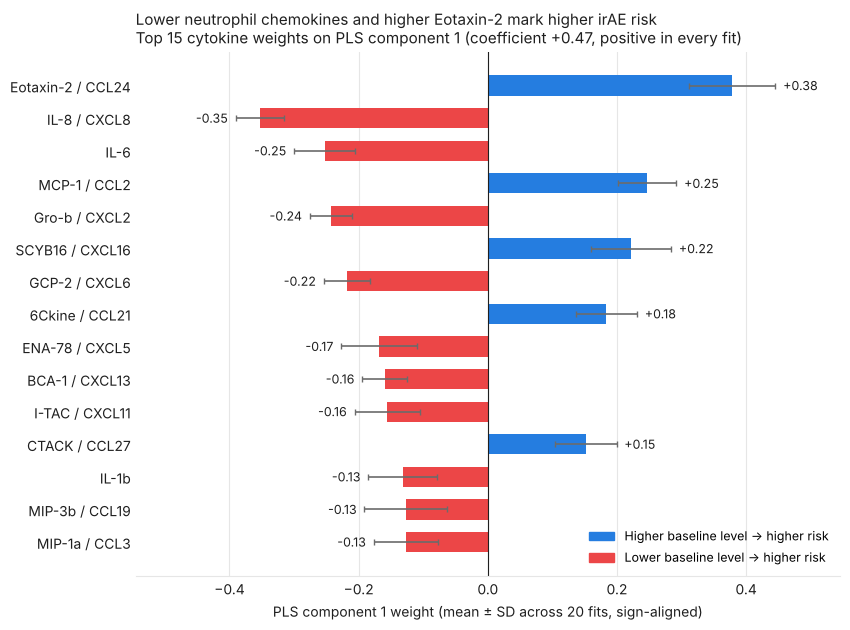

In [ ]:
# Figure: top 15 component-1 weights. Two hues = the two directions (a legend names them);
# labels and axes stay in neutral ink.
POS, NEG, INK, MUTED, GRID = "#257de0", "#ec4647", "#1f1f1f", "#6b6b6b", "#e6e6e6"

top = weights.head(15).iloc[::-1]
short = top["cytokine"].str.replace("/ ", " / ", regex=False)
colors = np.where(top["weight_mean"] > 0, POS, NEG)

fig, ax = plt.subplots(figsize=(8.6, 6.4))
ax.barh(short, top["weight_mean"], xerr=top["weight_sd"], color=colors, height=0.62,
        error_kw=dict(ecolor=MUTED, elinewidth=1.2, capsize=2.5))
ax.axvline(0, color=INK, lw=0.8)
for yi, (m, s) in enumerate(zip(top["weight_mean"], top["weight_sd"])):
    x = m + np.sign(m) * (s + 0.012)
    ax.text(x, yi, f"{m:+.2f}", va="center", ha="left" if m > 0 else "right",
            fontsize=9, color=INK)

lim = (top["weight_mean"].abs() + top["weight_sd"]).max() + 0.10
ax.set_xlim(-lim, lim)
ax.set_xlabel("PLS component 1 weight (mean ± SD across 20 fits, sign-aligned)", color=INK)
ax.set_title("Lower neutrophil chemokines and higher Eotaxin-2 mark higher irAE risk\n"
             f"Top 15 cytokine weights on PLS component 1 (coefficient {coef1:+.2f}, "
             "positive in every fit)", loc="left", fontsize=11, color=INK)
ax.legend(handles=[Patch(color=POS, label="Higher baseline level → higher risk"),
                   Patch(color=NEG, label="Lower baseline level → higher risk")],
          loc="lower right", frameon=False, fontsize=9)
ax.xaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.tick_params(colors=INK, length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
plt.tight_layout()
plt.savefig("fig_pls1_weights.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Permutation importance

Mean drop in held-out ROC AUC when one input variable is shuffled. This is computed on the
original inputs (individual cytokines, ANA, metadata) and reflects the **whole model** — all
three components plus ANA and metadata — not component 1 alone.

Read the SD column: where the SD is as large as the mean, that variable is not separable from
noise at this sample size.

In [ ]:
importance = pd.DataFrame({
    "feature": X.columns,
    "auc_drop_mean": PI.mean(axis=0),
    "auc_drop_sd": PI.std(axis=0),
    "folds_with_positive_drop": (PI > 0).sum(axis=0),
}).sort_values("auc_drop_mean", ascending=False).reset_index(drop=True)
importance.head(15).round(4)

,feature,auc_drop_mean,auc_drop_sd,folds_with_positive_drop
0,IL-8/ CXCL8,0.0474,0.0365,19
1,Eotaxin-2/ CCL24,0.0263,0.0323,16
2,cancer_group,0.0221,0.0202,18
3,GCP-2/ CXCL6,0.0195,0.0168,17
4,IL-2,0.0166,0.0285,13
5,ana_titer_baseline,0.0159,0.0286,15
6,IL-6,0.0149,0.0196,16
7,MCP-1/ CCL2,0.0139,0.0210,15
8,BCA-1/ CXCL13,0.0092,0.0217,15
9,Gro-b/ CXCL2,0.0091,0.0196,12


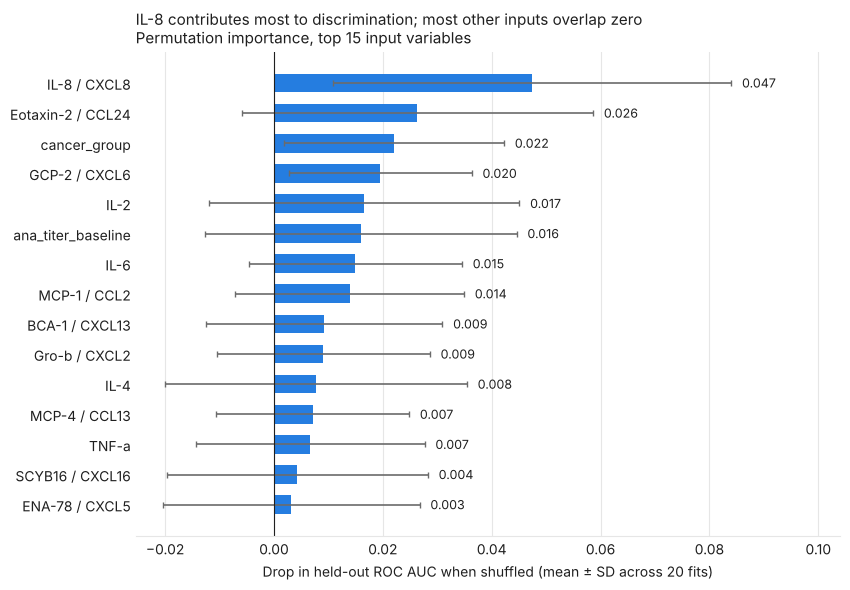

In [ ]:
top = importance.head(15).iloc[::-1]
short = top["feature"].str.replace("/ ", " / ", regex=False)

fig, ax = plt.subplots(figsize=(8.6, 6.0))
ax.barh(short, top["auc_drop_mean"], xerr=top["auc_drop_sd"], color=POS, height=0.62,
        error_kw=dict(ecolor=MUTED, elinewidth=1.2, capsize=2.5))
ax.axvline(0, color=INK, lw=0.8)
for yi, (m, s) in enumerate(zip(top["auc_drop_mean"], top["auc_drop_sd"])):
    ax.text(m + s + 0.002, yi, f"{m:.3f}", va="center", ha="left", fontsize=9, color=INK)
ax.set_xlabel("Drop in held-out ROC AUC when shuffled (mean ± SD across 20 fits)", color=INK)
ax.set_title("IL-8 contributes most to discrimination; most other inputs overlap zero\n"
             "Permutation importance, top 15 input variables", loc="left", fontsize=11,
             color=INK)
ax.set_xlim(min(0, (top["auc_drop_mean"] - top["auc_drop_sd"]).min()) - 0.005,
            (top["auc_drop_mean"] + top["auc_drop_sd"]).max() + 0.02)
ax.xaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.tick_params(colors=INK, length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
plt.tight_layout()
plt.savefig("fig_permutation_importance.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Exploratory follow-up analyses (descriptive)

These check the multivariate findings with simpler methods. **They use all 146 patients with
no cross-validation, and the cytokine groups in 7b–7c were defined after looking at the
component-1 weights.** Treat the p-values as descriptive and hypothesis-generating, not as
validated effect estimates.

### 7a. One cytokine at a time

Two-sided Mann–Whitney U test on raw baseline concentrations, grade ≥2 irAE vs grade 0–1,
with a Bonferroni threshold for 40 comparisons.

In [ ]:
rows = []
for c in cytokine_cols:
    a, b_ = df.loc[y == 1, c], df.loc[y == 0, c]
    rows.append({"cytokine": c,
                 "median_irAE": a.median(), "median_no_irAE": b_.median(),
                 "p_value": mannwhitneyu(a, b_, alternative="two-sided").pvalue})
univariate = pd.DataFrame(rows).sort_values("p_value").reset_index(drop=True)
univariate["higher_in"] = np.where(univariate["median_irAE"] > univariate["median_no_irAE"],
                                   "irAE", "no irAE")
bonf = 0.05 / len(cytokine_cols)
univariate["passes_bonferroni"] = univariate["p_value"] < bonf
print(f"Bonferroni threshold: p < {bonf:.5f}")
univariate.head(10).round(4)

Bonferroni threshold: p < 0.00125


,cytokine,median_irAE,median_no_irAE,p_value,higher_in,passes_bonferroni
0,IL-8/ CXCL8,7.03,10.35,0.0002,no irAE,True
1,Eotaxin-2/ CCL24,144.46,106.43,0.0022,irAE,False
2,IL-6,8.10,11.83,0.0145,no irAE,False
3,MCP-1/ CCL2,40.84,37.15,0.0699,irAE,False
4,BCA-1/ CXCL13,16.45,21.28,0.0833,no irAE,False
5,ENA-78/ CXCL5,88.50,149.72,0.0904,no irAE,False
6,GCP-2/ CXCL6,8.11,10.81,0.0908,no irAE,False
7,SCYB16/ CXCL16,395.98,357.69,0.1247,irAE,False
8,Gro-b/ CXCL2,66.86,73.76,0.1484,no irAE,False
9,MIG/ CXCL9,64.91,90.05,0.1523,no irAE,False


### 7b. How component 1's weight is distributed across cytokine families

Share of component 1's total squared weight carried by each functional group.

In [ ]:
GROUPS = {
    "Neutrophil chemokines (ELR+ CXC)": ["IL-8/ CXCL8", "Gro-b/ CXCL2", "GCP-2/ CXCL6",
                                         "ENA-78/ CXCL5", "Gro-a/ CXCL1"],
    "IL-6 / IL-1b / TNF-a":             ["IL-6", "IL-1b", "TNF-a"],
    "IFN-inducible / lymphoid-homing":  ["I-TAC/ CXCL11", "MIG/ CXCL9", "IP-10/ CXCL10",
                                         "BCA-1/ CXCL13", "MIP-3b/ CCL19"],
    "Positive pole (Eotaxin-2, MCP-1, CXCL16, CCL21, CCL27)":
                                        ["Eotaxin-2/ CCL24", "MCP-1/ CCL2", "SCYB16/ CXCL16",
                                         "6Ckine/ CCL21", "CTACK/ CCL27"],
}
wser = pd.Series(w_mean, index=cytokine_cols)
total = (wser**2).sum()
mass = pd.DataFrame([{"group": g,
                      "share_of_squared_weight_%": 100 * (wser[m]**2).sum() / total,
                      "member weights": ", ".join(f"{c.split('/')[0]} {wser[c]:+.2f}" for c in m)}
                     for g, m in GROUPS.items()])
print(f"Negative-weight cytokines: {100 * (wser[wser < 0]**2).sum() / total:.1f}% of squared "
      f"weight | positive-weight: {100 * (wser[wser > 0]**2).sum() / total:.1f}%")
pd.set_option("display.max_colwidth", 120)
mass.round(1)

Negative-weight cytokines: 55.3% of squared weight | positive-weight: 44.7%


,group,share_of_squared_weight_%,member weights
0,Neutrophil chemokines (ELR+ CXC),29.4,"IL-8 -0.35, Gro-b -0.24, GCP-2 -0.22, ENA-78 -0.17, Gro-a -0.03"
1,IL-6 / IL-1b / TNF-a,10.2,"IL-6 -0.25, IL-1b -0.13, TNF-a +0.09"
2,IFN-inducible / lymphoid-homing,9.4,"I-TAC -0.16, MIG -0.12, IP-10 +0.05, BCA-1 -0.16, MIP-3b -0.13"
3,"Positive pole (Eotaxin-2, MCP-1, CXCL16, CCL21, CCL27)",35.0,"Eotaxin-2 +0.38, MCP-1 +0.25, SCYB16 +0.22, 6Ckine +0.18, CTACK +0.15"


### 7c. Are the sub-signals independent?

Three scores, each oriented so that a higher score should mean higher risk, entered together
in one logistic regression:

- **Low neutrophil chemokines:** −(mean z-score of log IL-8, CXCL2, CXCL6, CXCL5)
- **Low IL-6 / IL-1β:** −(mean z-score of log IL-6, IL-1β)
- **High Eotaxin-2:** z-score of log Eotaxin-2/CCL24

If a score stays significant with the others in the model, it carries information the others
do not.

In [ ]:
Z = np.log1p(df[cytokine_cols])
Z = (Z - Z.mean()) / Z.std()

NEUT = ["IL-8/ CXCL8", "Gro-b/ CXCL2", "GCP-2/ CXCL6", "ENA-78/ CXCL5"]
scores = pd.DataFrame({
    "low_neutrophil_chemokines": -Z[NEUT].mean(axis=1),
    "low_IL6_IL1b": -Z[["IL-6", "IL-1b"]].mean(axis=1),
    "high_Eotaxin2": Z["Eotaxin-2/ CCL24"],
})
scores = (scores - scores.mean()) / scores.std()       # per-SD coefficients

fit = sm.Logit(y, sm.add_constant(scores)).fit(disp=0)
joint = fit.summary2().tables[1][["Coef.", "Std.Err.", "P>|z|"]]
print(joint.round(3).to_string())

print("\nSingle-score AUC (no model fitting):")
for c in scores:
    print(f"  {c:28s} {roc_auc_score(y, scores[c]):.3f}")
print("\nCorrelations between scores:")
print(scores.corr().round(2).to_string())
print(f"\nIL-8 vs IL-6 (log scale): r = {Z['IL-8/ CXCL8'].corr(Z['IL-6']):.2f} | "
      f"IL-8 vs IL-1b: r = {Z['IL-8/ CXCL8'].corr(Z['IL-1b']):.2f}")

                           Coef.  Std.Err.  P>|z|
const                      0.184     0.179  0.304
low_neutrophil_chemokines  0.478     0.202  0.018
low_IL6_IL1b               0.183     0.196  0.351
high_Eotaxin2              0.604     0.200  0.003

Single-score AUC (no model fitting):
  low_neutrophil_chemokines    0.644
  low_IL6_IL1b                 0.597
  high_Eotaxin2                0.647

Correlations between scores:
                           low_neutrophil_chemokines  low_IL6_IL1b  high_Eotaxin2
low_neutrophil_chemokines                       1.00          0.39           0.11
low_IL6_IL1b                                    0.39          1.00           0.05
high_Eotaxin2                                   0.11          0.05           1.00

IL-8 vs IL-6 (log scale): r = 0.62 | IL-8 vs IL-1b: r = 0.56


### 7d. Sensitivity check: detection limits

ENA-78/CXCL5 was flagged below the assay's detection limit in 44% of patients in the source
data; a third of all patients had no reported value and sit at the imputed floor (printed
below). Its values therefore partly record whether it was detectable at all. This repeats 7c
with CXCL5 left out of the neutrophil score, to check that the finding does not depend on it.

In [ ]:
floor_share = pd.Series({c: (df[c] == df[c].min()).mean() * 100 for c in NEUT + ["IL-6", "IL-1b"]})
print("Patients at the lowest recorded value (%):")
print(floor_share.round(1).to_string())

s2 = scores.copy()
s2["low_neutrophil_chemokines"] = -Z[["IL-8/ CXCL8", "Gro-b/ CXCL2", "GCP-2/ CXCL6"]].mean(axis=1)
s2 = (s2 - s2.mean()) / s2.std()
fit2 = sm.Logit(y, sm.add_constant(s2)).fit(disp=0)
print("\nJoint regression without CXCL5 in the neutrophil score:")
print(fit2.summary2().tables[1][["Coef.", "Std.Err.", "P>|z|"]].round(3).to_string())

Patients at the lowest recorded value (%):
IL-8/ CXCL8       0.7
Gro-b/ CXCL2      4.1
GCP-2/ CXCL6      6.8
ENA-78/ CXCL5    33.6
IL-6             11.0
IL-1b             0.7

Joint regression without CXCL5 in the neutrophil score:
                           Coef.  Std.Err.  P>|z|
const                      0.182     0.179  0.310
low_neutrophil_chemokines  0.489     0.213  0.022
low_IL6_IL1b               0.137     0.204  0.500
high_Eotaxin2              0.630     0.202  0.002


## 8. Save tables

Written to the Colab working directory (Files panel on the left → download).

In [ ]:
stability.to_csv("irae_component_stability.csv", index=False)
weights.to_csv("irae_pls1_weights.csv", index=False)
importance.to_csv("irae_permutation_importance.csv", index=False)
univariate.to_csv("irae_univariate_tests.csv", index=False)
print("Saved 4 tables and 2 figures:", sorted(f for f in os.listdir(".")
      if f.startswith(("irae_", "fig_"))))

Saved 4 tables and 2 figures: ['fig_permutation_importance.png', 'fig_pls1_weights.png', 'irae_component_stability.csv', 'irae_permutation_importance.csv', 'irae_pls1_weights.csv', 'irae_univariate_tests.csv']


## 9. Findings

**Component 1 is the only interpretable axis.** Its coefficient is positive in all 20 fits
(+0.470 ± 0.074) and 20 of 40 weights never change sign. Component 2 has a stable direction
(+0.254 ± 0.037) but unstable make-up (6 of 40 weights stable). Component 3 is unstable in both
(coefficient −0.031 ± 0.303, positive in 9 of 20 fits; 1 of 40 weights stable).

**Component 1 has two opposing poles.**

- *Lower baseline level → higher risk:* IL-8/CXCL8 (−0.353), IL-6 (−0.253), CXCL2 (−0.243),
  CXCL6 (−0.218), CXCL5 (−0.169), CXCL13 (−0.160), CXCL11 (−0.156), IL-1β (−0.132). The
  neutrophil-recruiting chemokines carry 29.4% of the component's squared weight.
- *Higher baseline level → higher risk:* Eotaxin-2/CCL24 (+0.378, the largest weight),
  MCP-1/CCL2 (+0.246), CXCL16 (+0.222), CCL21 (+0.184), CCL27 (+0.152).

**Permutation importance** ranks IL-8 first (AUC drop 0.047 ± 0.037), then Eotaxin-2
(0.026 ± 0.032), cancer group (0.022 ± 0.020) and CXCL6 (0.020 ± 0.017). SDs are about as
large as the means, so only the leading features are clearly separable from noise.

**Simple tests agree in direction.** IL-8 is lower in patients with a grade ≥2 irAE (median
7.0 vs 10.4; p = 0.0002, passes Bonferroni). Eotaxin-2 is higher (144.5 vs 106.4; p = 0.002)
and IL-6 lower (8.1 vs 11.8; p = 0.015); neither passes Bonferroni.

**Two independent signals (exploratory).** In the joint regression, the low-neutrophil-chemokine
score (β = 0.48 per SD, p = 0.018) and Eotaxin-2 (β = 0.60 per SD, p = 0.003) each stay
significant and are nearly uncorrelated (r = 0.11). The IL-6/IL-1β score adds nothing of its
own (β = 0.18, p = 0.35). Leaving CXCL5 out of the neutrophil score does not change this
(β = 0.49, p = 0.022).

## Caveats

- **Small sample (n = 146), one cohort, no external validation.** Everything here is internal
  to one retrospective dataset.
- **Associations, not causes.** A PLS weight is a cytokine's contribution *within a model of
  correlated predictors*; it can partly stand in for correlated neighbours.
- **Only the leading features are robust.** For most variables the permutation-importance SD
  is as large as the mean.
- **Section 7 is exploratory.** Groups were defined after seeing the weights, and those
  analyses use all patients without cross-validation.
- **Fixed C.** Interpretation uses C = 0.1; notebook 3's headline AUC used C tuned per fold.
- **Detection limits.** Several cytokines have many values at the assay floor (CXCL5 most of
  all); half-minimum imputation for unquantifiable values was done on the full dataset before
  cross-validation.
- **Re-analysis.** Khan et al. (2025) analysed this same dataset, so agreement with their
  conclusions is not independent replication.